# Projet Machine Learning

# Analyse intelligente du marché automobile marocain

Master Intelligence Artificielle

Objectifs :

- Scraping Web
- Nettoyage des données
- Analyse Exploratoire
- Machine Learning
- Clustering

In [305]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LinearRegression

from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor

from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.model_selection import GridSearchCV

from sklearn.cluster import KMeans

import math

import warnings
warnings.filterwarnings("ignore")

In [ ]:
df = pd.read_csv("../data/cars_clean.csv")


In [307]:
df.head()

,Marque_Modele,Prix,Ville,Annee,Boite,Carburant,Kilometrage,Lien
0,Dacia Logan,179000.0,Tanger,2024,Manuelle,Diesel,17000,https://www.moteur.ma/fr/voiture/achat-voiture...
1,Mercedes-Benz Classe C,328000.0,Casablanca,2018,Automatique,Diesel,119000,https://www.moteur.ma/fr/voiture/achat-voiture...
2,DS 5,109000.0,Casablanca,2013,Automatique,Diesel,190000,https://www.moteur.ma/fr/voiture/achat-voiture...
3,Audi A5,170500.0,Casablanca,2011,Automatique,Diesel,242000,https://www.moteur.ma/fr/voiture/achat-voiture...
4,Kia Picanto,56000.0,Casablanca,2008,Manuelle,Essence,180000,https://www.moteur.ma/fr/voiture/achat-voiture...


In [308]:
df.shape

(849, 8)

In [309]:
#Verification
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 849 entries, 0 to 848
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Marque_Modele  849 non-null    str    
 1   Prix           849 non-null    float64
 2   Ville          849 non-null    str    
 3   Annee          849 non-null    int64  
 4   Boite          849 non-null    str    
 5   Carburant      849 non-null    str    
 6   Kilometrage    849 non-null    int64  
 7   Lien           849 non-null    str    
dtypes: float64(1), int64(2), str(5)
memory usage: 53.2 KB


In [310]:
df.describe(include="all")

,Marque_Modele,Prix,Ville,Annee,Boite,Carburant,Kilometrage,Lien
count,849,8.490000e+02,849,849.000000,849,849,849.000000,849
unique,232,NaN,20,NaN,2,4,NaN,849
top,Hyundai Tucson,NaN,Casablanca,NaN,Manuelle,Diesel,NaN,https://www.moteur.ma/fr/voiture/achat-voiture...
freq,23,NaN,248,NaN,528,663,NaN,1
mean,NaN,2.186668e+05,NaN,2014.416961,NaN,NaN,135365.939929,NaN
std,NaN,8.952137e+05,NaN,7.946193,NaN,NaN,108412.538917,NaN
min,NaN,1.000000e+00,NaN,1980.000000,NaN,NaN,0.000000,NaN
25%,NaN,7.500000e+04,NaN,2010.000000,NaN,NaN,50000.000000,NaN
50%,NaN,1.250000e+05,NaN,2016.000000,NaN,NaN,130000.000000,NaN
75%,NaN,2.000000e+05,NaN,2021.000000,NaN,NaN,200000.000000,NaN


#Nettoyage

In [311]:
df.isnull().sum()

Marque_Modele    0
Prix             0
Ville            0
Annee            0
Boite            0
Carburant        0
Kilometrage      0
Lien             0
dtype: int64

In [312]:
df.drop_duplicates(inplace=True)

In [313]:
df["Ville"] = df["Ville"].fillna("Inconnue")

In [314]:
df["Annee"] = df["Annee"].fillna(df["Annee"].median())

In [315]:
#Nettoyage Prix

df["Prix"] = (
    df["Prix"]
    .astype(str)
    .str.replace("MAD", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df["Prix"] = pd.to_numeric(df["Prix"], errors="coerce")

In [316]:
#Nettoyage Kilométrage

df["Kilometrage"] = (
    df["Kilometrage"]
    .astype(str)
    .str.replace("km", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df["Kilometrage"] = pd.to_numeric(
    df["Kilometrage"],
    errors="coerce"
)

In [317]:
df.dropna(inplace=True)

In [318]:
df.to_csv(
    "../data/cars_clean.csv",
    index=False
)

#EDA

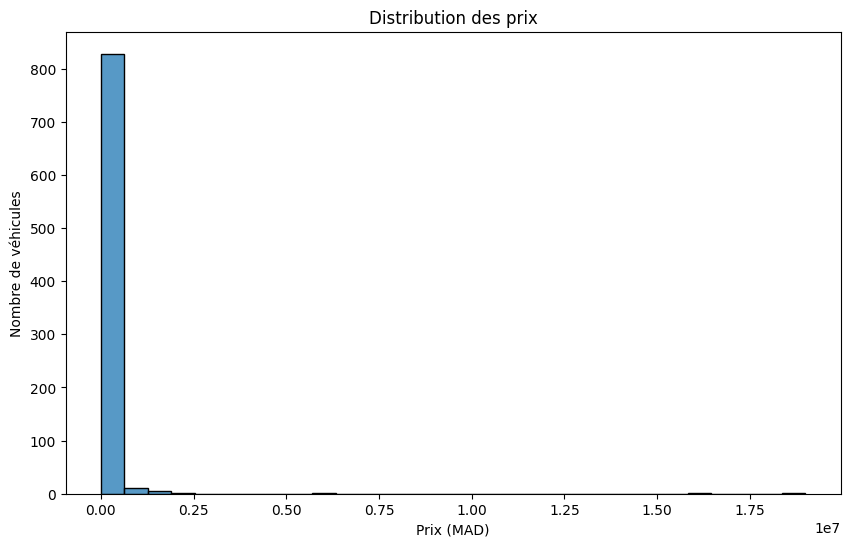

In [319]:
#Distribution des prix
plt.figure(figsize=(10,6))

sns.histplot(df["Prix"], bins=30)

plt.title("Distribution des prix")

plt.xlabel("Prix (MAD)")

plt.ylabel("Nombre de véhicules")

plt.show()

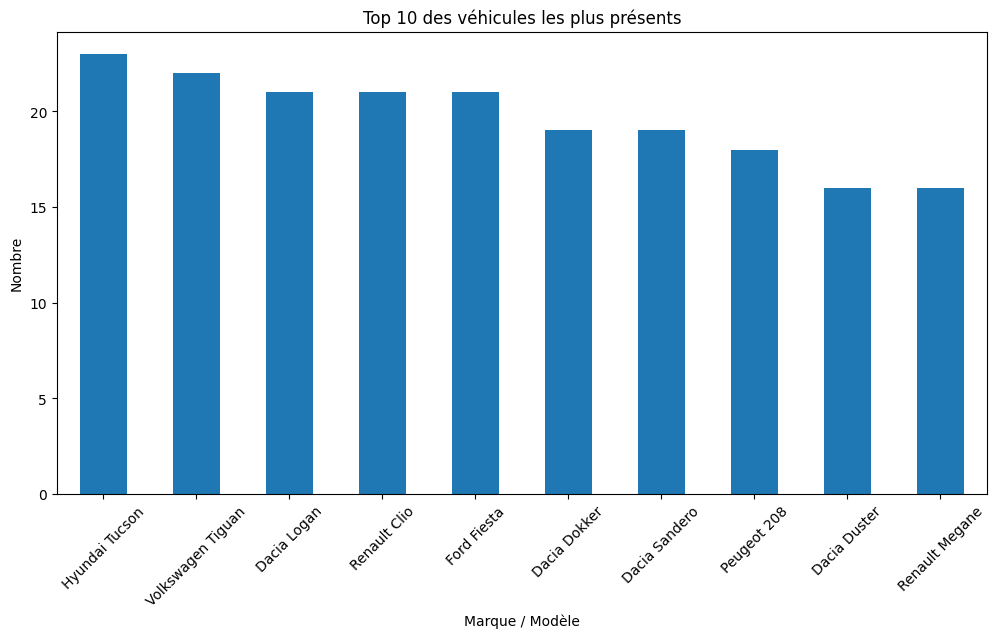

In [320]:
#Top 10 des marques
plt.figure(figsize=(12,6))

df["Marque_Modele"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 des véhicules les plus présents")

plt.xlabel("Marque / Modèle")

plt.ylabel("Nombre")

plt.xticks(rotation=45)

plt.show()

Text(0.5, 1.0, 'Répartition des carburants')

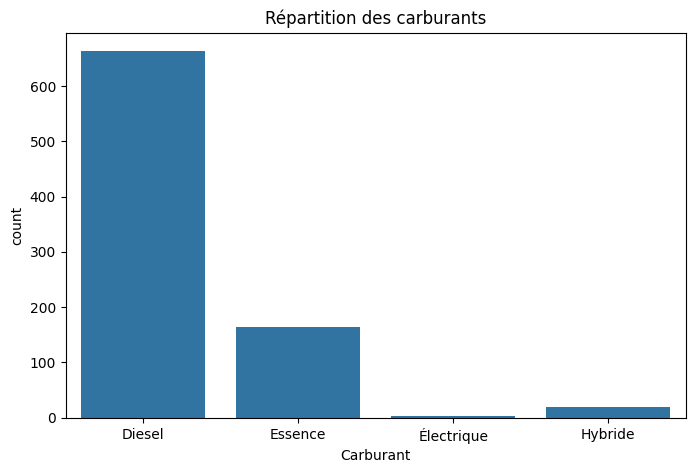

In [321]:
#Répartition des carburants
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Carburant")

plt.title("Répartition des carburants")

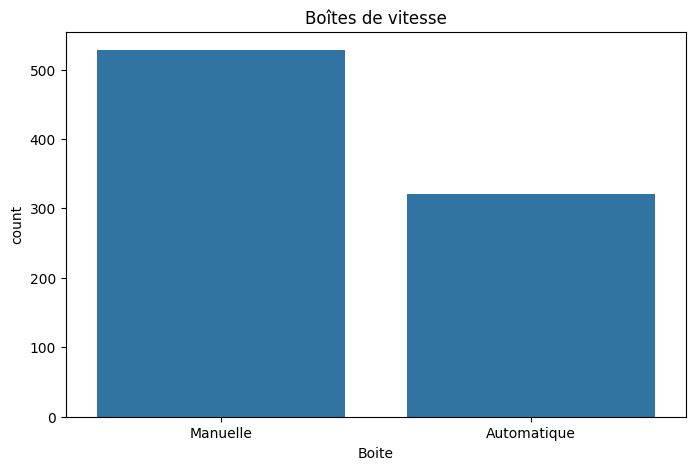

In [322]:
#Répartition des boîtes de vitesse
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Boite")

plt.title("Boîtes de vitesse")

plt.show()

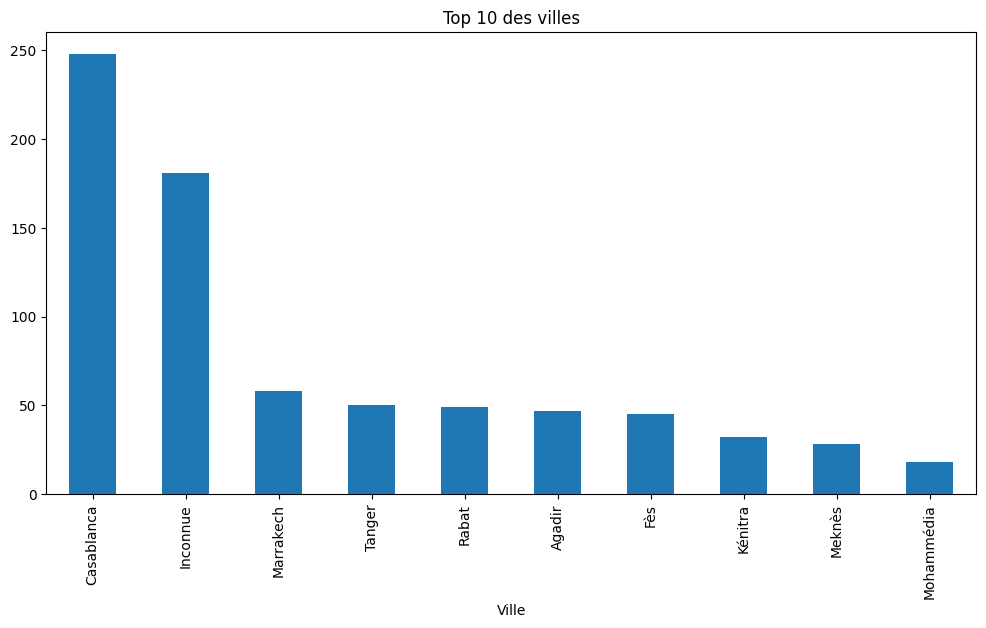

In [323]:
#Top 10 des villes
plt.figure(figsize=(12,6))

df["Ville"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 des villes")

plt.show()

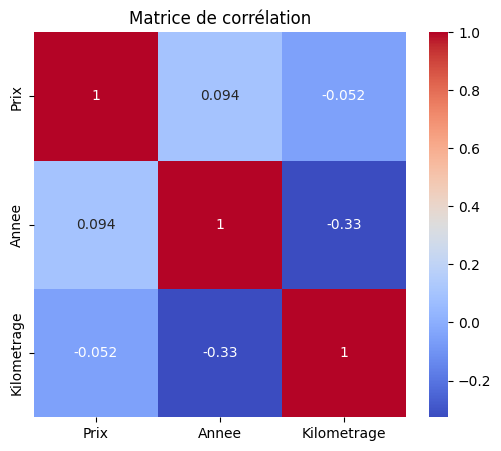

In [324]:
#Corrélation
corr = df[["Prix","Annee","Kilometrage"]].corr()

plt.figure(figsize=(6,5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title("Matrice de corrélation")

plt.show()

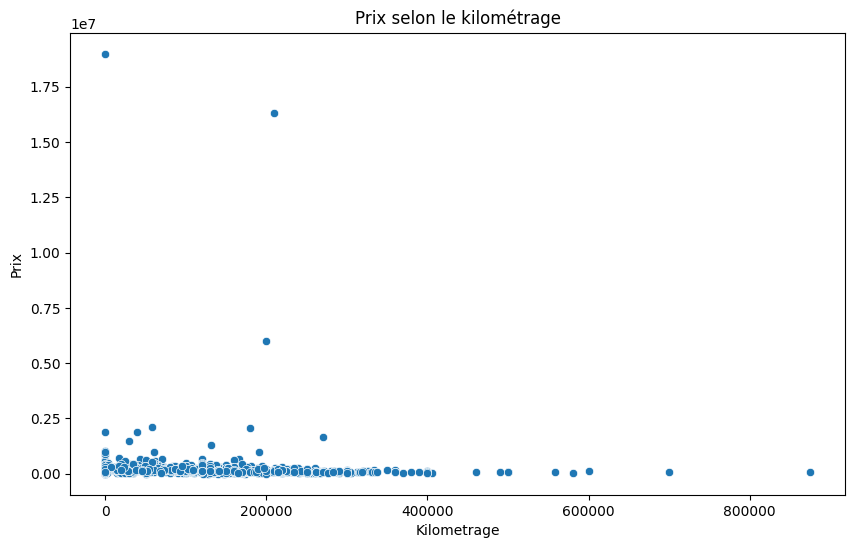

In [325]:
#Prix vs Kilométrage
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="Kilometrage",
    y="Prix"
)

plt.title("Prix selon le kilométrage")

plt.show()

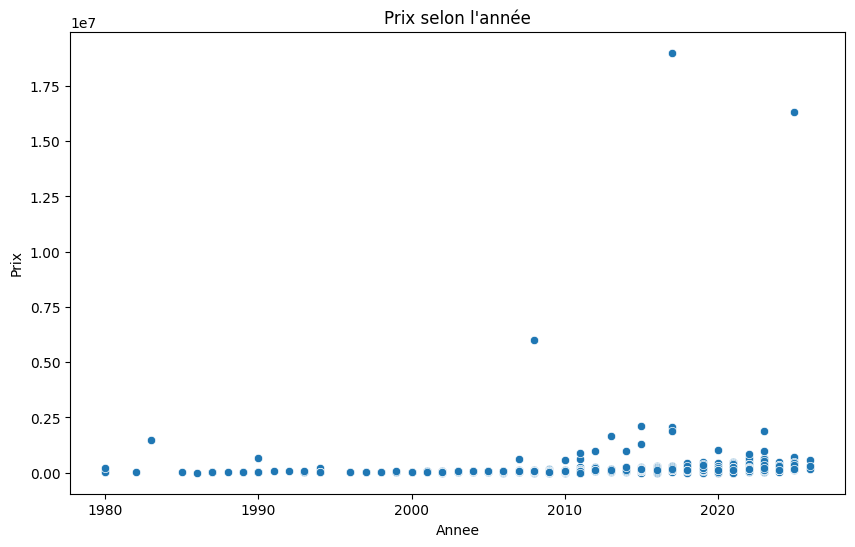

In [326]:
#Prix vs Année
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="Annee",
    y="Prix"
)

plt.title("Prix selon l'année")

plt.show()

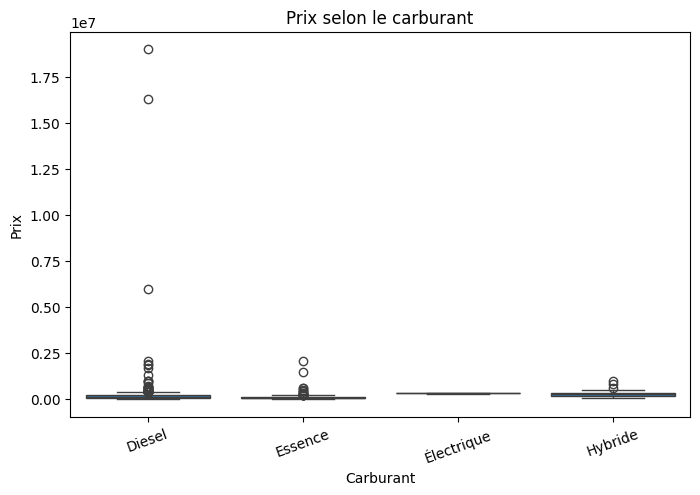

In [327]:
#Prix par carburant
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Carburant",
    y="Prix"
)

plt.title("Prix selon le carburant")

plt.xticks(rotation=20)

plt.show()

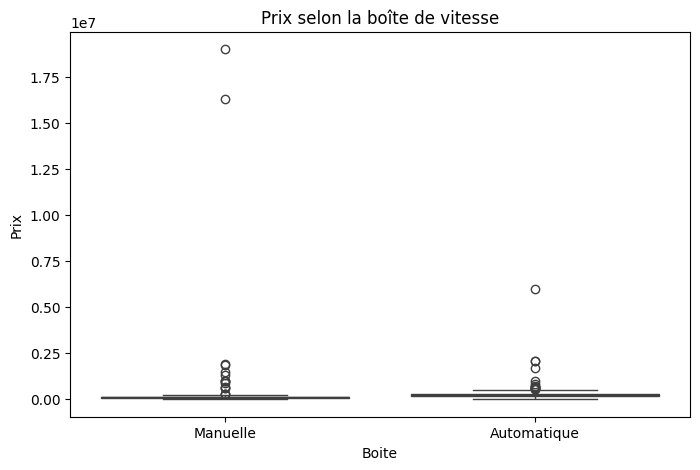

In [328]:
#Prix par boîte
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Boite",
    y="Prix"
)

plt.title("Prix selon la boîte de vitesse")

plt.show()

#Prétraitement

1.LabelEncoder

In [329]:
Q1 = df["Prix"].quantile(0.25)

Q3 = df["Prix"].quantile(0.75)

IQR = Q3 - Q1

borne_inf = Q1 - 1.5 * IQR

borne_sup = Q3 + 1.5 * IQR

df = df[
    (df["Prix"] >= borne_inf)
    &
    (df["Prix"] <= borne_sup)
]

print(df.shape)

(798, 8)


In [330]:
# Encodage One-Hot

df = pd.get_dummies(
    df,
    columns=[
        "Marque_Modele",
        "Ville",
        "Boite",
        "Carburant"
    ],
    drop_first=True
)

In [331]:
#Definir X et y pour predire

X = df.drop(columns=["Prix","Lien"])

y = df["Prix"]

In [332]:

scaler = StandardScaler()

X = scaler.fit_transform(X)

2. Train/Test Split

In [333]:
#Train/Test Split


X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.2,

    random_state=42

)

In [334]:
#verification

print(X_train.shape)

print(X_test.shape)

print(y_train.shape)

print(y_test.shape)

(638, 246)
(160, 246)
(638,)
(160,)


Machine Learning
1. Construction des modèles

In [335]:
#Linear Regression

linear = LinearRegression()

# Entraînement du modèle

linear.fit(X_train, y_train)

# Prédiction

prediction_linear = linear.predict(X_test)

# Évaluation du modèle

mae_linear = mean_absolute_error(y_test, prediction_linear)

mse_linear = mean_squared_error(y_test, prediction_linear)

rmse_linear = math.sqrt(mse_linear)

r2_linear = r2_score(y_test, prediction_linear)

print("Linear Regression")

print("MAE :", mae_linear)

print("RMSE :", rmse_linear)

print("R² :",  r2_linear)

Linear Regression
MAE : 33062.822635903874
RMSE : 47487.96631898293
R² : 0.7011182804458007


In [336]:

#Random Forest



forest = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

# Entraînement du modèle

forest.fit(X_train, y_train)

# Prédiction

prediction_forest = forest.predict(X_test)

# Évaluation du modèle

mae_forest = mean_absolute_error(y_test, prediction_forest)

mse_forest = mean_squared_error(y_test, prediction_forest)

rmse_forest = math.sqrt(mse_forest)

r2_forest = r2_score(y_test, prediction_forest)


print("===== Random Forest =====")
print("MAE :", mae_forest)
print("RMSE :", rmse_forest)
print("R² :", r2_forest)

===== Random Forest =====
MAE : 27988.35657018849
RMSE : 43161.455142217725
R² : 0.7530981370855392


In [337]:
#XGBoost

xgb = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    random_state=42
)

# Entraînement du modèle

xgb.fit(X_train, y_train)

# Prédiction

prediction_xgb = xgb.predict(X_test)

# Évaluation du modèle

mae_xgb = mean_absolute_error(y_test, prediction_xgb)

mse_xgb = mean_squared_error(y_test, prediction_xgb)

rmse_xgb = math.sqrt(mse_xgb)

r2_xgb = r2_score(y_test, prediction_xgb)



print("===== XGBoost =====")
print("MAE :", mae_xgb)
print("RMSE :", rmse_xgb)
print("R² :", r2_xgb)

===== XGBoost =====
MAE : 28609.188024902345
RMSE : 41577.30337137672
R² : 0.7708895768595381


In [338]:
#Comparaison des modeles

resultats = pd.DataFrame({

    "Modèle":[

        "Linear Regression",

        "Random Forest",

        "XGBoost"

    ],

    "MAE":[

        mae_linear,

        mae_forest,

        mae_xgb

    ],

    "RMSE":[

        rmse_linear,

        rmse_forest,

        rmse_xgb

    ],

    "R²":[

        r2_linear,

        r2_forest,

        r2_xgb

    ]

})

print(resultats)

              Modèle           MAE          RMSE        R²
0  Linear Regression  33062.822636  47487.966319  0.701118
1      Random Forest  27988.356570  43161.455142  0.753098
2            XGBoost  28609.188025  41577.303371  0.770890


##Validation croisée

In [339]:
#Linear Regression
scores_linear = cross_val_score(

    LinearRegression(),

    X,

    y,

    cv=5,

    scoring="r2"

)

print(scores_linear)

print("Moyenne :", scores_linear.mean())

[0.40786953 0.43660469 0.62639773 0.41459647 0.51447607]
Moyenne : 0.4799888988379625


In [340]:
#Random Forest
scores_forest = cross_val_score(

    RandomForestRegressor(random_state=42),

    X,

    y,

    cv=5,

    scoring="r2"

)

print(scores_forest)

print("Moyenne :", scores_forest.mean())

[0.7884877  0.50390532 0.75524299 0.68724261 0.62677446]
Moyenne : 0.6723306158989136


In [341]:
#XGBoost
scores_xgb = cross_val_score(

    XGBRegressor(random_state=42),

    X,

    y,

    cv=5,

    scoring="r2"

)

print(scores_xgb)

print("Moyenne :", scores_xgb.mean())

[0.77608211 0.49242482 0.75820485 0.71608094 0.67356005]
Moyenne : 0.6832705547227713


In [342]:
#comparaison
cv = pd.DataFrame({

    "Modèle":[

        "Linear Regression",

        "Random Forest",

        "XGBoost"

    ],

    "Score Moyen R²":[

        scores_linear.mean(),

        scores_forest.mean(),

        scores_xgb.mean()

    ]

})

print(cv)

              Modèle  Score Moyen R²
0  Linear Regression        0.479989
1      Random Forest        0.672331
2            XGBoost        0.683271


##l'optimisation des hyperparamètres (GridSearchCV).

In [343]:
#Paramètres à tester
param_grid = {

    "n_estimators":[100,200,300],

    "max_depth":[10,20,30,None],

    "min_samples_split":[2,5,10],

    "min_samples_leaf":[1,2,4]

}

In [344]:
#Création du modèle
rf = RandomForestRegressor(
    random_state=42
)

In [345]:
#GridSearchCV
grid = GridSearchCV(

    estimator=rf,

    param_grid=param_grid,

    cv=5,

    scoring="r2",

    n_jobs=-1

)

In [346]:
#Entraînement
grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [10, 20, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and para

In [347]:
#Meilleurs paramètres
print(grid.best_params_)

{'max_depth': 30, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}


In [348]:
#Meilleur score
print(grid.best_score_)

0.6618617948713098


In [349]:
#Utiliser le meilleur modèle
best_model = grid.best_estimator_

In [350]:
#Prédiction
prediction = best_model.predict(X_test)

In [351]:
#Évaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

mae = mean_absolute_error(y_test, prediction)

rmse = np.sqrt(mean_squared_error(y_test, prediction))

r2 = r2_score(y_test, prediction)

print("MAE :", mae)
print("RMSE :", rmse)
print("R² :", r2)

MAE : 28437.633072083107
RMSE : 43882.74871149803
R² : 0.7447769721885442


#Clustering (K-Means)

In [352]:
cluster_data = df[

    [

        "Prix",

        "Annee",

        "Kilometrage"

    ]

]

In [353]:
#Standardisation

scaler = StandardScaler()

cluster_scaled = scaler.fit_transform(cluster_data)

In [354]:
#Création du modèle

kmeans = KMeans(

    n_clusters=3,

    random_state=42

)

In [355]:
#Entraînement

df["Cluster"] = kmeans.fit_predict(cluster_scaled)

In [356]:
print(df.head())

       Prix  Annee  Kilometrage  \
0  179000.0   2024        17000   
1  328000.0   2018       119000   
2  109000.0   2013       190000   
3  170500.0   2011       242000   
4   56000.0   2008       180000   

                                                Lien  \
0  https://www.moteur.ma/fr/voiture/achat-voiture...   
1  https://www.moteur.ma/fr/voiture/achat-voiture...   
2  https://www.moteur.ma/fr/voiture/achat-voiture...   
3  https://www.moteur.ma/fr/voiture/achat-voiture...   
4  https://www.moteur.ma/fr/voiture/achat-voiture...   

   Marque_Modele_Alfa Romeo Giulietta  Marque_Modele_Alfa Romeo Stelvio  \
0                               False                             False   
1                               False                             False   
2                               False                             False   
3                               False                             False   
4                               False                             False   

 

In [357]:
#Nombre de voitures par Cluster

print(

df["Cluster"].value_counts()

)

Cluster
2    402
1    290
0    106
Name: count, dtype: int64


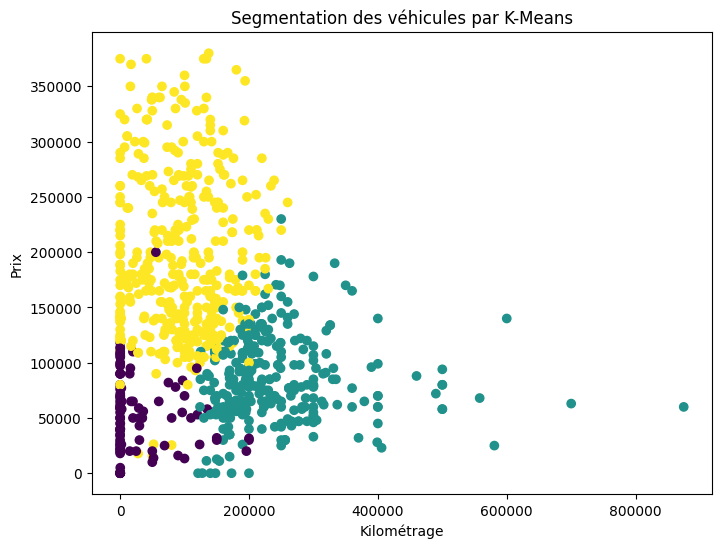

In [358]:
#Visualisation

import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(

    df["Kilometrage"],

    df["Prix"],

    c=df["Cluster"]

)

plt.xlabel("Kilométrage")

plt.ylabel("Prix")

plt.title("Segmentation des véhicules par K-Means")

plt.show()

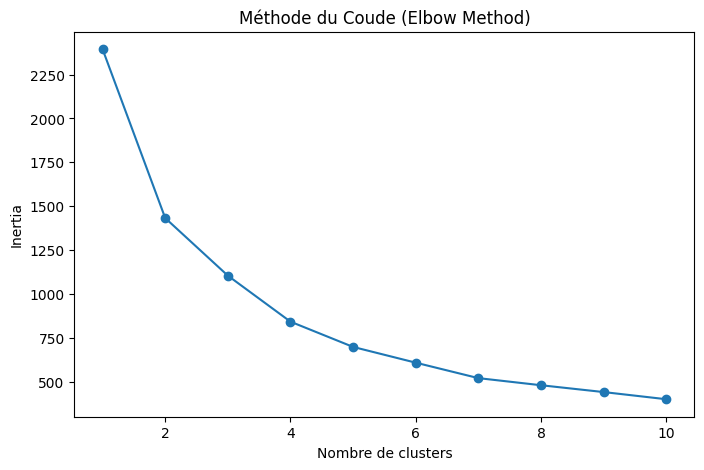

In [359]:
inertia = []

for k in range(1,11):

    model = KMeans(

        n_clusters=k,

        random_state=42

    )

    model.fit(cluster_scaled)

    inertia.append(model.inertia_)

plt.figure(figsize=(8,5))

plt.plot(range(1,11), inertia, marker="o")

plt.xlabel("Nombre de clusters")

plt.ylabel("Inertia")

plt.title("Méthode du Coude (Elbow Method)")

plt.show()

In [360]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

df["Cluster"] = kmeans.fit_predict(cluster_scaled)

print(df.head())

       Prix  Annee  Kilometrage  \
0  179000.0   2024        17000   
1  328000.0   2018       119000   
2  109000.0   2013       190000   
3  170500.0   2011       242000   
4   56000.0   2008       180000   

                                                Lien  \
0  https://www.moteur.ma/fr/voiture/achat-voiture...   
1  https://www.moteur.ma/fr/voiture/achat-voiture...   
2  https://www.moteur.ma/fr/voiture/achat-voiture...   
3  https://www.moteur.ma/fr/voiture/achat-voiture...   
4  https://www.moteur.ma/fr/voiture/achat-voiture...   

   Marque_Modele_Alfa Romeo Giulietta  Marque_Modele_Alfa Romeo Stelvio  \
0                               False                             False   
1                               False                             False   
2                               False                             False   
3                               False                             False   
4                               False                             False   

 

In [361]:
print(df["Cluster"].value_counts())

Cluster
2    402
1    290
0    106
Name: count, dtype: int64


In [362]:
#Calculer les moyennes de chaque cluster


cluster_resume = df.groupby("Cluster")[["Prix","Annee","Kilometrage"]].mean()

print(cluster_resume)

                  Prix        Annee    Kilometrage
Cluster                                           
0         53293.707547  2004.613208   27867.990566
1         84644.268966  2009.868966  241662.417241
2        195480.360697  2019.746269   94548.992537


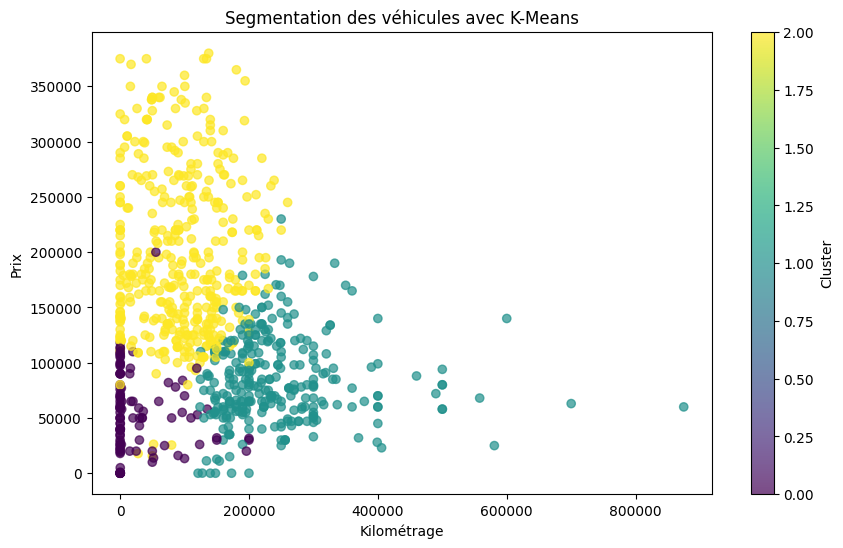

In [363]:
plt.figure(figsize=(10,6))

plt.scatter(
    df["Kilometrage"],
    df["Prix"],
    c=df["Cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Kilométrage")
plt.ylabel("Prix")
plt.title("Segmentation des véhicules avec K-Means")

plt.colorbar(label="Cluster")

plt.show()

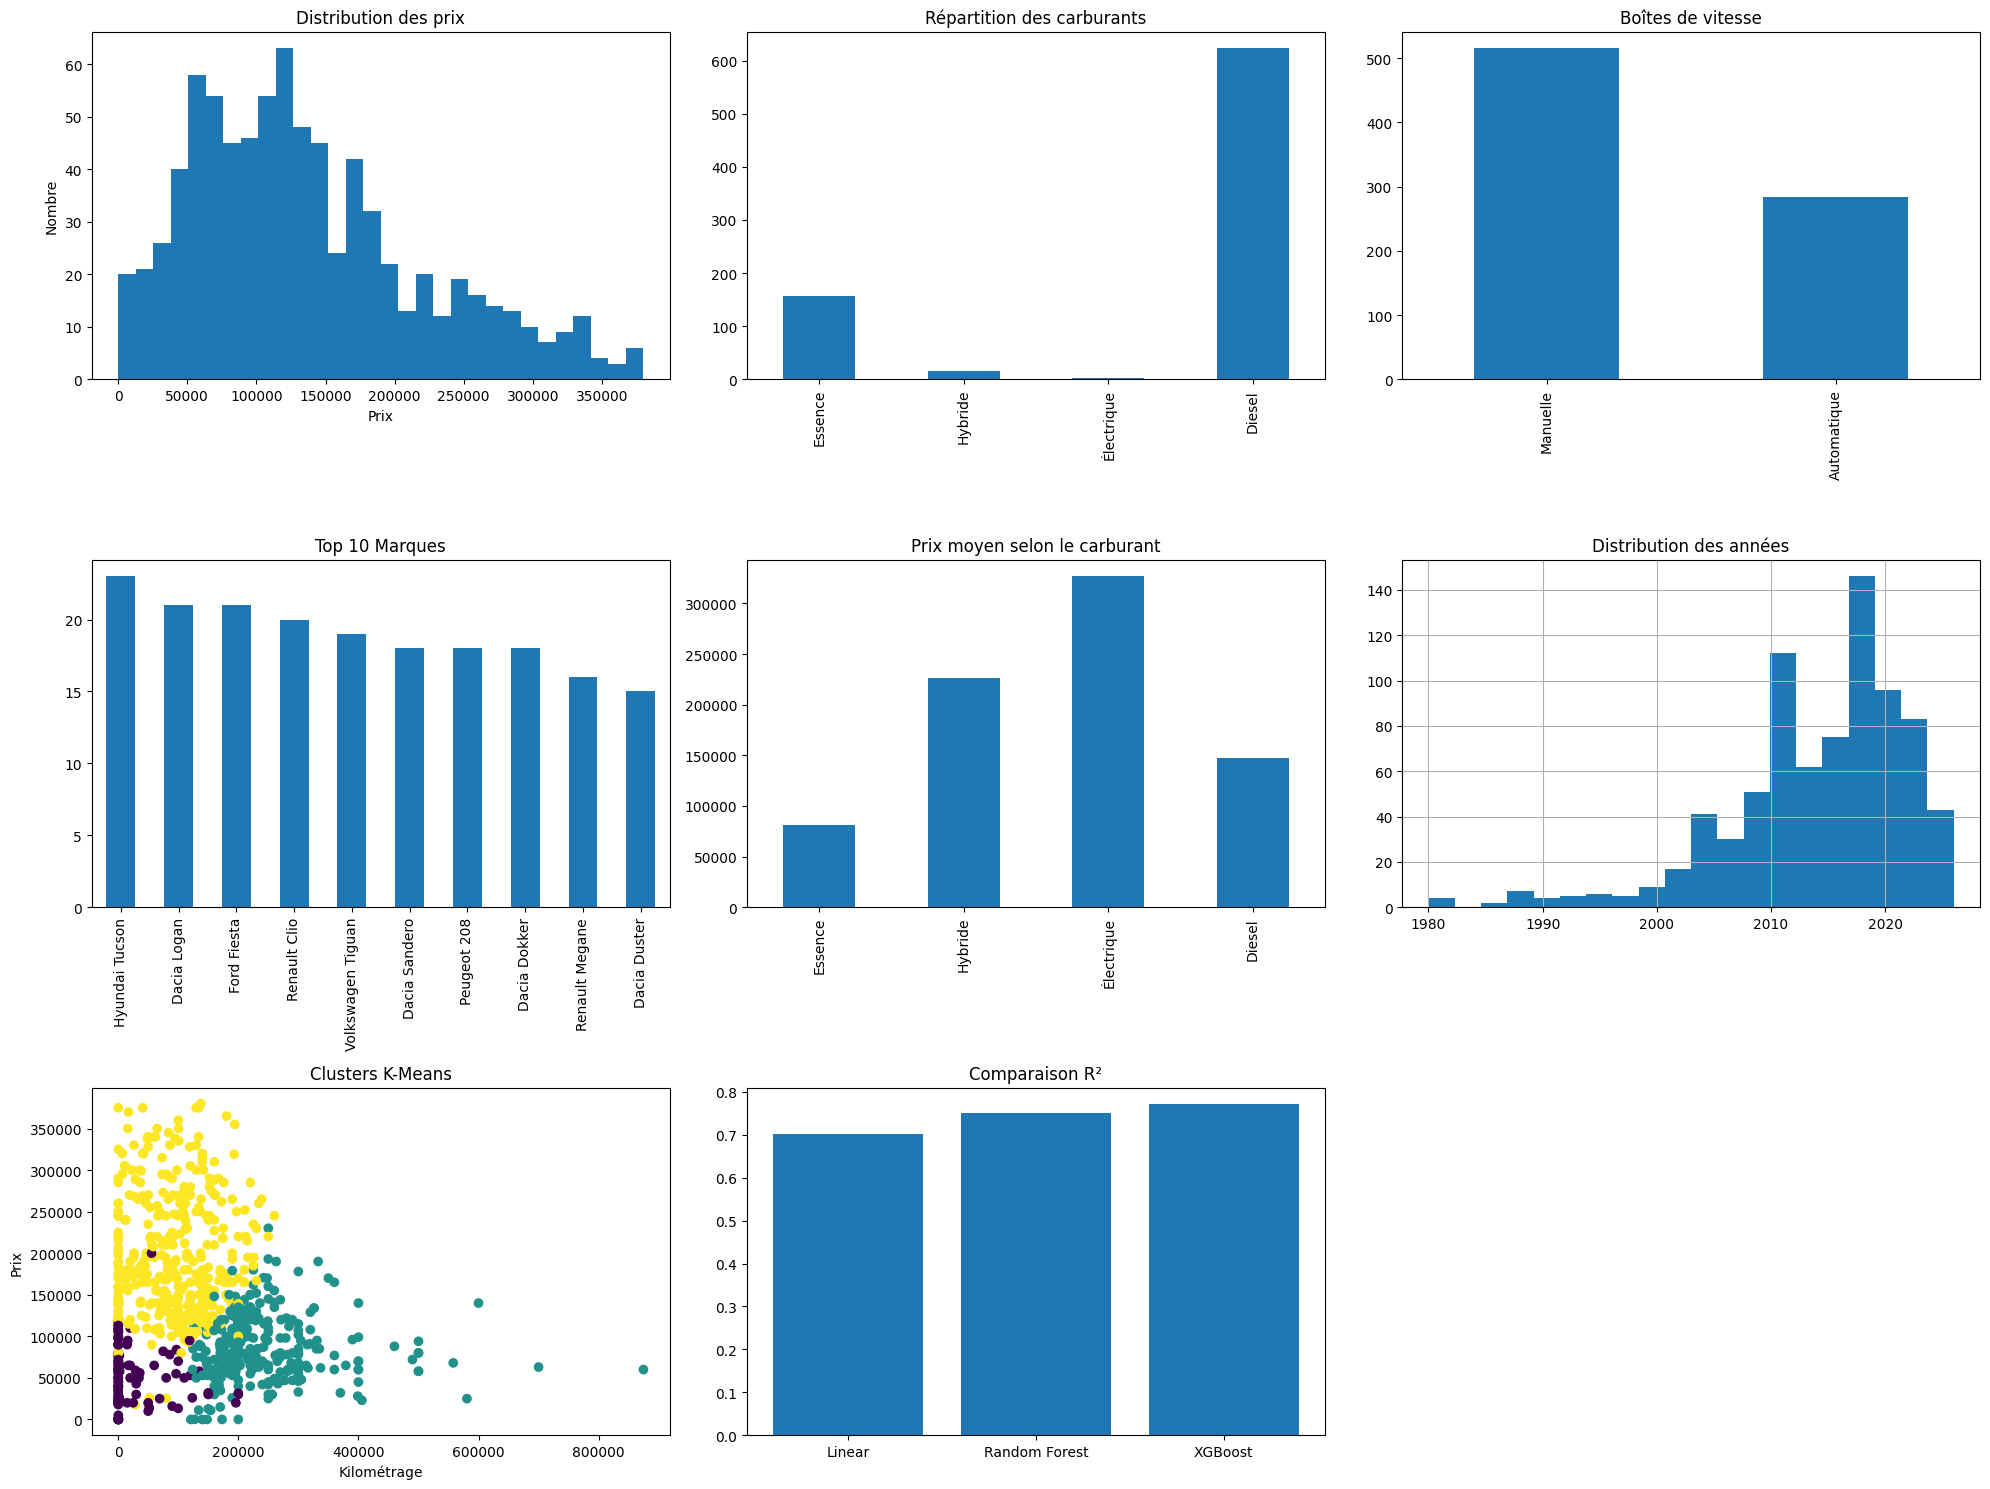

In [366]:
import matplotlib.pyplot as plt
import pandas as pd

plt.figure(figsize=(20,15))

###################################################
# 1 Distribution des prix
###################################################
plt.subplot(3,3,1)
plt.hist(df["Prix"], bins=30)
plt.title("Distribution des prix")
plt.xlabel("Prix")
plt.ylabel("Nombre")

###################################################
# 2 Répartition des carburants
###################################################
plt.subplot(3,3,2)

carburants = {
    "Essence": df["Carburant_Essence"].sum(),
    "Hybride": df["Carburant_Hybride"].sum(),
    "Électrique": df["Carburant_Électrique"].sum(),
}

# Diesel = lignes où toutes les colonnes carburant = 0
diesel = ((df["Carburant_Essence"] == 0) &
           (df["Carburant_Hybride"] == 0) &
           (df["Carburant_Électrique"] == 0)).sum()

carburants["Diesel"] = diesel

pd.Series(carburants).plot(kind="bar")
plt.title("Répartition des carburants")

###################################################
# 3 Répartition des boîtes de vitesse
###################################################
plt.subplot(3,3,3)

boites = {
    "Manuelle": df["Boite_Manuelle"].sum(),
    "Automatique": (df["Boite_Manuelle"] == 0).sum()
}

pd.Series(boites).plot(kind="bar")
plt.title("Boîtes de vitesse")

###################################################
# 4 Top 10 marques
###################################################
plt.subplot(3,3,4)

marque_cols = [col for col in df.columns if col.startswith("Marque_Modele_")]
top_marques = df[marque_cols].sum().sort_values(ascending=False).head(10)

top_marques.index = top_marques.index.str.replace("Marque_Modele_", "")
top_marques.plot(kind="bar")
plt.title("Top 10 Marques")

###################################################
# 5 Prix moyen selon le carburant
###################################################
plt.subplot(3,3,5)

prix_carburant = {
    "Essence": df.loc[df["Carburant_Essence"] == 1, "Prix"].mean(),
    "Hybride": df.loc[df["Carburant_Hybride"] == 1, "Prix"].mean(),
    "Électrique": df.loc[df["Carburant_Électrique"] == 1, "Prix"].mean(),
    "Diesel": df.loc[(df["Carburant_Essence"] == 0) &
                       (df["Carburant_Hybride"] == 0) &
                       (df["Carburant_Électrique"] == 0), "Prix"].mean()
}

pd.Series(prix_carburant).plot(kind="bar")
plt.title("Prix moyen selon le carburant")

###################################################
# 6 Distribution des années
###################################################
plt.subplot(3,3,6)
df["Annee"].hist(bins=20)
plt.title("Distribution des années")

###################################################
# 7 Clustering
###################################################
plt.subplot(3,3,7)
plt.scatter(
    df["Kilometrage"],
    df["Prix"],
    c=df["Cluster"],
    cmap="viridis"
)
plt.title("Clusters K-Means")
plt.xlabel("Kilométrage")
plt.ylabel("Prix")

###################################################
# 8 Comparaison des modèles
###################################################
plt.subplot(3,3,8)
modeles = ["Linear", "Random Forest", "XGBoost"]
scores = [0.701, 0.751, 0.771]
plt.bar(modeles, scores)
plt.title("Comparaison R²")

###################################################

plt.tight_layout()
plt.show()